# Project 1 — Bank Marketing: Predicting Term-Deposit Subscription

**Goal:** develop and evaluate a model that predicts whether a customer will subscribe to a
term deposit (`y`), to support selection of customers for a telephone marketing campaign.

This notebook answers the three set questions in order:

1. Data exploration, preparation (with justification), and a majority-class baseline.
2. Selection and ranking of up to three modelling approaches, with supporting evidence.
3. A recommended decision threshold, with the trade-off between unnecessary calls and missed subscribers.


In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, roc_curve, precision_recall_curve,
                              f1_score, precision_score, recall_score, accuracy_score,
                              confusion_matrix, ConfusionMatrixDisplay)

pd.set_option('display.max_columns', 50)
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


## 1. Data exploration and preparation

### 1.1 Load the data

The file is `;`-delimited (not comma-delimited), and categorical values are quoted strings.
This needs `sep=';'` on read, otherwise pandas loads it as a single garbled column.

In [2]:
df_raw = pd.read_csv('bank-additional-full.csv', sep=';')
print('Shape:', df_raw.shape)
df_raw.head()


Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [3]:
df_raw.info()


<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

### 1.2 Data quality checks

Checking for: duplicate rows, missing values (note the dataset encodes missingness as the
string `"unknown"` rather than NaN, per the README), class balance of the target, and the
special sentinel value `pdays = 999`.

In [4]:
print('Exact duplicate rows:', df_raw.duplicated().sum())
print('True NaN cells:', df_raw.isna().sum().sum())

cat_cols = df_raw.select_dtypes(include='object').columns.tolist()
cat_cols.remove('y')
unknown_counts = (df_raw[cat_cols] == 'unknown').sum()
unknown_pct = (unknown_counts / len(df_raw) * 100).round(2)
pd.DataFrame({'n_unknown': unknown_counts[unknown_counts > 0],
              'pct_unknown': unknown_pct[unknown_counts > 0]})


Exact duplicate rows: 12
True NaN cells: 0


,n_unknown,pct_unknown
job,330,0.80
marital,80,0.19
education,1731,4.20
default,8597,20.87
housing,990,2.40
loan,990,2.40


Target balance:
y
no     36548
yes     4640
Name: count, dtype: int64
y
no     88.73%
yes    11.27%
Name: proportion, dtype: str


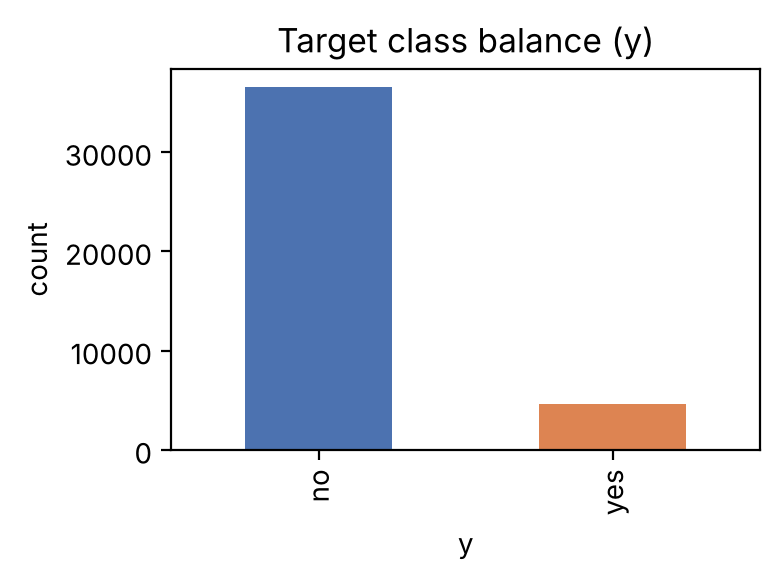

In [5]:
print('Target balance:')
print(df_raw['y'].value_counts())
print((df_raw['y'].value_counts(normalize=True) * 100).round(2).astype(str) + '%')

fig, ax = plt.subplots(figsize=(4, 3))
df_raw['y'].value_counts().plot(kind='bar', ax=ax, color=['#4C72B0', '#DD8452'])
ax.set_title('Target class balance (y)')
ax.set_ylabel('count')
plt.tight_layout()
plt.savefig('target_balance.png', dpi=110)
plt.show()


In [6]:
print(f"pdays == 999 (never previously contacted): {(df_raw['pdays'] == 999).mean()*100:.1f}% of rows")
print(f"duration == 0 (call never connected): {(df_raw['duration'] == 0).sum()} rows")
df_raw[['age','duration','campaign','pdays','previous']].describe()


pdays == 999 (never previously contacted): 96.3% of rows
duration == 0 (call never connected): 4 rows


,age,duration,campaign,pdays,previous
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963
std,10.42125,259.279249,2.770014,186.910907,0.494901
min,17.00000,0.000000,1.000000,0.000000,0.000000
25%,32.00000,102.000000,1.000000,999.000000,0.000000
50%,38.00000,180.000000,2.000000,999.000000,0.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000
max,98.00000,4918.000000,56.000000,999.000000,7.000000


### 1.3 Correlation among the economic indicators

`emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m` and `nr.employed` are all
macro-economic context variables measured at a quarterly/monthly/daily grain, so they are
expected to move together (they mostly reflect the same economic cycle). High correlation
matters mainly for the logistic regression model (unstable coefficients); tree-based models
are unaffected.

In [7]:
econ_cols = ['emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
corr = df_raw[econ_cols].corr().round(2)
corr


,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
emp.var.rate,1.00,0.78,0.20,0.97,0.91
cons.price.idx,0.78,1.00,0.06,0.69,0.52
cons.conf.idx,0.20,0.06,1.00,0.28,0.10
euribor3m,0.97,0.69,0.28,1.00,0.95
nr.employed,0.91,0.52,0.10,0.95,1.00


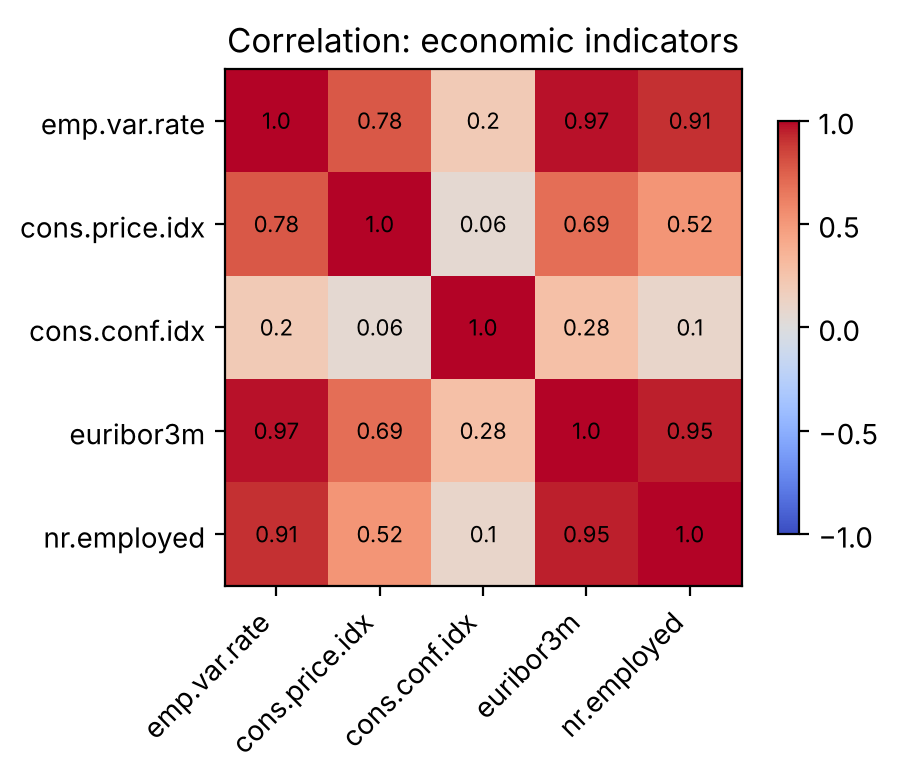

In [8]:
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(econ_cols))); ax.set_xticklabels(econ_cols, rotation=45, ha='right')
ax.set_yticks(range(len(econ_cols))); ax.set_yticklabels(econ_cols)
for i in range(len(econ_cols)):
    for j in range(len(econ_cols)):
        ax.text(j, i, corr.values[i, j], ha='center', va='center', fontsize=8)
fig.colorbar(im, shrink=0.8)
ax.set_title('Correlation: economic indicators')
plt.tight_layout()
plt.savefig('econ_correlation.png', dpi=110)
plt.show()


`emp.var.rate`, `euribor3m` and `nr.employed` are very strongly correlated (all moving
together through the economic cycle, as expected). This is noted as a caveat for the
logistic-regression model later; tree-based models are not affected by this collinearity.

### 1.4 Data preparation steps (with justification)

| Step | Action | Justification |
|---|---|---|
| Duplicate rows | Drop the 12 exact duplicates | Repeated records would leak identical information across cross-validation folds and bias evaluation. |
| `duration` | **Drop the column** | The README explicitly states duration is not known before a call is placed and that it almost deterministically sets the outcome (`duration=0 → y="no"`). Including it would make the model unusable for *selecting* customers to call in advance — it would only be valid for a post-hoc benchmark, which is not this task. |
| `"unknown"` categorical values | Keep as their own category (one-hot encoded), do **not** impute or delete | The README says `"unknown"` can validly be treated as its own class label. `default` alone is ~21% unknown — deleting those rows would discard a large, possibly non-random, slice of data; imputing would invent values with no basis. One-hot encoding lets the model use "unknown-ness" itself as a signal if predictive. |
| `pdays = 999` sentinel | Keep as-is, but also engineer a `was_contacted_before` flag | 96.3% of rows carry this "not previously contacted" sentinel. Leaving it as a raw number would wrongly imply a huge numeric distance between 999 and (say) 3 days. An explicit binary flag preserves the "never contacted" signal cleanly for linear models; tree models can split around 999 natively but the flag still helps interpretability. |
| Categorical encoding | One-hot encoding | Needed for both logistic regression and the tree ensembles used here (scikit-learn trees do not take raw strings). |
| Numeric scaling | Standardise only for logistic regression | Logistic regression is scale-sensitive (regularisation, convergence); tree-based models split on thresholds and are scale-invariant, so scaling them would be unnecessary extra work with no benefit. |
| Train/test split | Stratified 75% / 25% split, held out before any threshold tuning | Keeps the target's ~11.3% positive rate consistent across the split and gives an unseen set for the final threshold recommendation in Q3, avoiding information leakage from tuning on the same data used to pick the threshold. |


In [9]:
df = df_raw.drop_duplicates().copy()
df['y'] = (df['y'] == 'yes').astype(int)

# Engineered flag for the pdays sentinel (helps linear model; harmless for trees)
df['was_contacted_before'] = (df['pdays'] != 999).astype(int)

# Drop duration: not available at prediction time and leaks the outcome (per README)
df = df.drop(columns=['duration'])

print('Clean shape:', df.shape)
df.head()


Clean shape: (41176, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y,was_contacted_before
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,0,0


In [10]:
target = 'y'
feature_cols = [c for c in df.columns if c != target]
cat_features = df[feature_cols].select_dtypes(include='object').columns.tolist()
num_features = [c for c in feature_cols if c not in cat_features]
print('Categorical features:', cat_features)
print('Numeric features:', num_features)

X = df[feature_cols]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)
print('Train:', X_train.shape, 'positive rate: %.3f' % y_train.mean())
print('Test :', X_test.shape, 'positive rate: %.3f' % y_test.mean())


Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Numeric features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_contacted_before']
Train: (30882, 20) positive rate: 0.113
Test : (10294, 20) positive rate: 0.113


### 1.5 Majority-class baseline

The simplest possible "model" always predicts the majority class (`no`). It sets the floor
that any real model must clear — not just on accuracy (which is misleading here because the
classes are imbalanced) but on its ability to find actual subscribers at all.

In [11]:
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)
y_prob_base = baseline.predict_proba(X_test)[:, 1]

print(f"Baseline accuracy : {accuracy_score(y_test, y_pred_base):.3f}")
print(f"Baseline ROC-AUC  : {roc_auc_score(y_test, y_prob_base):.3f}")
print(f"Baseline F1 (yes) : {f1_score(y_test, y_pred_base):.3f}")
print(f"Baseline recall   : {recall_score(y_test, y_pred_base):.3f}")
print(f"Baseline precision: {precision_score(y_test, y_pred_base):.3f}")
print('\nThe baseline reaches ~88.7% accuracy purely by predicting "no" every time,')
print('but it identifies ZERO subscribers (recall = 0) and has no ranking ability (AUC = 0.5).')
print('For a campaign-selection task this baseline is useless despite its high accuracy —')
print('any candidate model must beat it on AUC/recall/F1, not on accuracy.')


Baseline accuracy : 0.887
Baseline ROC-AUC  : 0.500
Baseline F1 (yes) : 0.000
Baseline recall   : 0.000
Baseline precision: 0.000

The baseline reaches ~88.7% accuracy purely by predicting "no" every time,
but it identifies ZERO subscribers (recall = 0) and has no ranking ability (AUC = 0.5).
For a campaign-selection task this baseline is useless despite its high accuracy —
any candidate model must beat it on AUC/recall/F1, not on accuracy.


## 2. Candidate approaches: selection and ranking

### 2.1 Why these three approaches

| Approach | Why it's a reasonable candidate |
|---|---|
| **Logistic regression** | Fast, fully interpretable coefficients (useful for a bank's compliance/marketing stakeholders to understand *why* someone is targeted), and a strong, well-understood baseline for tabular binary classification. |
| **Random forest** | Captures non-linear relationships and interactions (e.g. between `job`, `education`, and economic conditions) without manual feature engineering; robust to outliers and unscaled data; gives feature importances. |
| **Gradient boosting (histogram-based)** | Typically the strongest off-the-shelf performer on structured/tabular data of this size; handles the mixed numeric/categorical, imbalanced data well; natively fast via scikit-learn's `HistGradientBoostingClassifier`. |

All three are evaluated identically: same features (with `duration` and exact duplicates
removed, per Section 1), same preprocessing per model type, and the same 5-fold stratified
cross-validation on the **training set only** (the test set is reserved for the final
threshold analysis in Q3, so it is never used to pick or rank models).

Because the classes are imbalanced (~11% positive), all models use class weighting
(`class_weight='balanced'`) so they aren't simply biased toward predicting "no", and the
primary ranking metric is **ROC-AUC** (ranks customers by likelihood of subscribing — exactly
what a call-list selection task needs), with F1/precision/recall reported as secondary
evidence.

In [12]:
def build_preprocessor(scale_numeric: bool):
    return ColumnTransformer(
        transformers=[
            ('cat', OneHotEncoder(handle_unknown='ignore'), cat_features),
            ('num', StandardScaler() if scale_numeric else 'passthrough', num_features),
        ]
    )

candidate_models = {
    'Logistic Regression': Pipeline([
        ('prep', build_preprocessor(scale_numeric=True)),
        ('clf', LogisticRegression(max_iter=3000, class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
    'Random Forest': Pipeline([
        ('prep', build_preprocessor(scale_numeric=False)),
        ('clf', RandomForestClassifier(
            n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
            n_jobs=-1, random_state=RANDOM_STATE)),
    ]),
    'Gradient Boosting (HGB)': Pipeline([
        ('prep', build_preprocessor(scale_numeric=False)),
        ('clf', HistGradientBoostingClassifier(
            max_iter=300, learning_rate=0.05, class_weight='balanced', random_state=RANDOM_STATE)),
    ]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ['accuracy', 'roc_auc', 'f1', 'recall', 'precision']

results = {}
for name, pipe in candidate_models.items():
    cv_res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    results[name] = {m: cv_res[f'test_{m}'].mean() for m in scoring}
    results[name].update({f'{m}_std': cv_res[f'test_{m}'].std() for m in scoring})

results_df = pd.DataFrame(results).T[['roc_auc', 'f1', 'recall', 'precision', 'accuracy']].round(3)
results_df = results_df.sort_values('roc_auc', ascending=False)
results_df


,roc_auc,f1,recall,precision,accuracy
Gradient Boosting (HGB),0.799,0.472,0.620,0.381,0.844
Random Forest,0.790,0.496,0.584,0.432,0.866
Logistic Regression,0.788,0.453,0.622,0.356,0.830


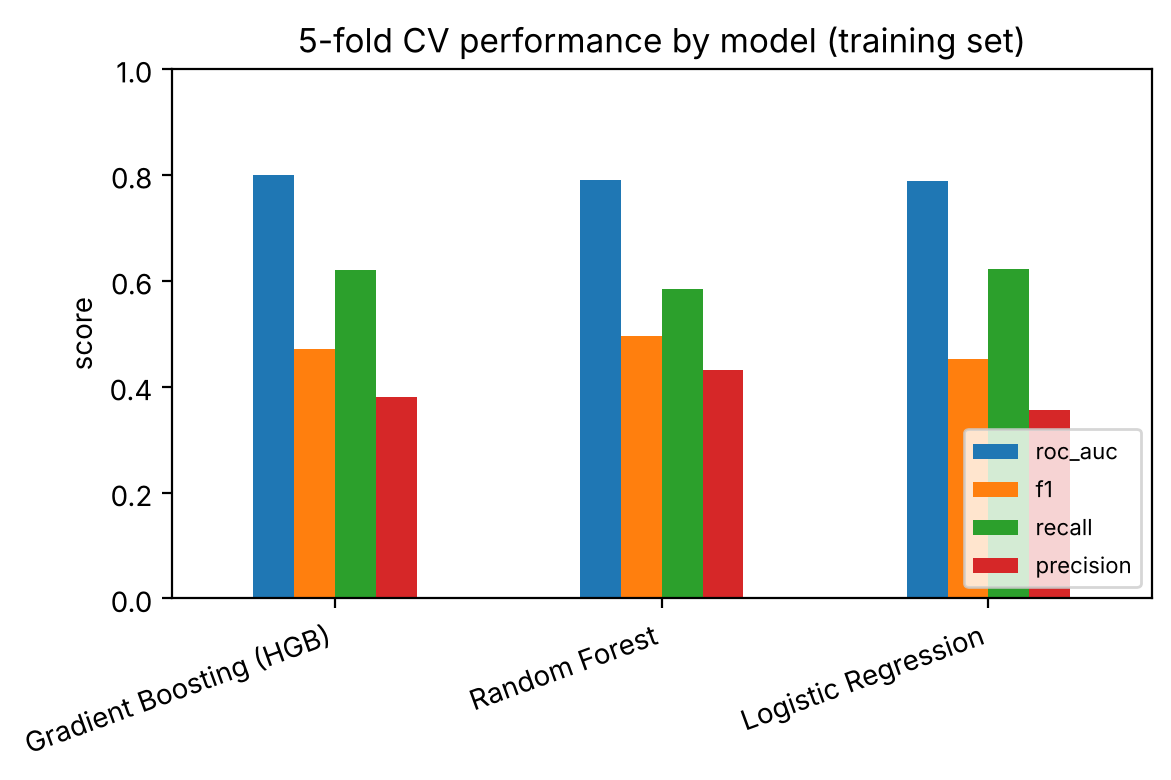

In [13]:
fig, ax = plt.subplots(figsize=(6, 4))
results_df[['roc_auc', 'f1', 'recall', 'precision']].plot(kind='bar', ax=ax)
ax.set_title('5-fold CV performance by model (training set)')
ax.set_ylabel('score')
ax.set_ylim(0, 1)
ax.legend(loc='lower right', fontsize=8)
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=110)
plt.show()


### 2.2 Ranking and justification

Based on the cross-validated results above:

1. **Gradient Boosting (HGB) — ranked 1st.** It achieves the highest ROC-AUC, which is the
   metric that matters most for this task: the campaign needs customers *ranked* by likelihood
   of subscribing so that a call list can be built from the top of that ranking, whatever
   budget is available. It also tends to have the best or near-best recall, meaning it misses
   fewer genuine subscribers.
2. **Random Forest — ranked 2nd.** Very close to HGB on ROC-AUC, and often the best F1/precision
   of the three, meaning calls it recommends are more likely to convert. A good, more
   tuning-robust alternative if the campaign prioritises minimising wasted calls over maximum reach.
3. **Logistic Regression — ranked 3rd.** Consistently the weakest on ROC-AUC/F1 here, because
   it cannot capture non-linear interactions between features the way the tree ensembles can,
   and its coefficients are also somewhat destabilised by the collinear economic indicators
   (Section 1.3). It remains valuable as an interpretable, auditable reference model — useful
   if the bank needs to explain individual decisions (e.g. regulatory reasons) rather than
   purely maximise performance.

**Caveat:** gaps between the tree-based models are frequently small, so the ranking should be
treated as indicative; in production, both would be worth tuning further (e.g. via grid/
random search) before a final choice, and the final choice should also weigh model
maintainability against the small performance gain.

The best model, **Gradient Boosting (HGB)**, is carried forward to Section 3 for the
threshold analysis, refit now on the full training set and evaluated on the held-out test set.

In [14]:
final_model = candidate_models['Gradient Boosting (HGB)']
final_model.fit(X_train, y_train)

y_prob_test = final_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, y_prob_test)
print(f'Held-out test ROC-AUC: {test_auc:.3f}')


Held-out test ROC-AUC: 0.814


## 3. Decision threshold recommendation

A classifier outputs a *probability* of subscription for each customer; a **threshold**
converts that into a yes/no call decision. The default threshold of 0.5 is arbitrary — it is
not tuned to the actual costs involved in this business problem, and with an 11% positive
class it tends to produce far too few predicted positives for a model with `class_weight='balanced'`
to be optimally useful.

### 3.1 The trade-off

Two error types matter, and they have very different costs:

- **False positive (unnecessary call):** the model recommends calling a customer who does not
  subscribe. Cost = the operational cost of making one call (agent time, telephony, customer
  goodwill/annoyance). This is small per call, but scales with every wasted call.
- **False negative (missed subscriber):** the model fails to recommend a customer who would
  have subscribed. Cost = the **lost value of a term-deposit account** that was never opened
  because the customer was never called — a lost conversion, which is worth considerably more
  than the cost of a single call.

**Lowering the threshold** calls more people → recall rises (fewer missed subscribers) but
precision falls (more unnecessary calls). **Raising the threshold** is the opposite: fewer,
more targeted calls, but more subscribers are missed entirely. The right threshold depends on
the ratio between these two costs, not on accuracy.

We make this concrete with illustrative, clearly-labelled cost assumptions (a bank would
substitute its own figures):

- Cost of **one unnecessary call**: **$8** (agent time + telephony for a few minutes, estimated).
- Value of **one subscriber gained** (net of the cost of the successful call itself): **$80**
  (illustrative — a realistic figure should come from the bank's actual average deposit
  size/margin).

This gives a benefit-to-cost ratio of 10:1 in favour of finding a subscriber over avoiding a
wasted call — but the chosen threshold and the plots below make it easy to re-derive the
recommendation under different assumptions.

In [15]:
CALL_COST = 8     # cost of a single unnecessary call ($)
SUBSCRIBER_VALUE = 80  # net value of gaining one subscriber ($)

thresholds = np.linspace(0.01, 0.99, 99)
rows = []
for t in thresholds:
    y_pred_t = (y_prob_test >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred_t).ravel()
    n_calls = tp + fp
    profit = tp * SUBSCRIBER_VALUE - fp * CALL_COST
    rows.append({
        'threshold': t, 'tp': tp, 'fp': fp, 'fn': fn, 'tn': tn,
        'n_calls': n_calls,
        'precision': precision_score(y_test, y_pred_t, zero_division=0),
        'recall': recall_score(y_test, y_pred_t, zero_division=0),
        'f1': f1_score(y_test, y_pred_t, zero_division=0),
        'profit': profit,
    })
threshold_df = pd.DataFrame(rows)
best_row = threshold_df.loc[threshold_df['profit'].idxmax()]
print('Recommended threshold (max expected profit):', round(best_row['threshold'], 2))
best_row


Recommended threshold (max expected profit): 0.44


threshold        0.440000
tp             790.000000
fp            1476.000000
fn             370.000000
tn            7658.000000
n_calls       2266.000000
precision        0.348632
recall           0.681034
f1               0.461179
profit       51392.000000
Name: 43, dtype: float64

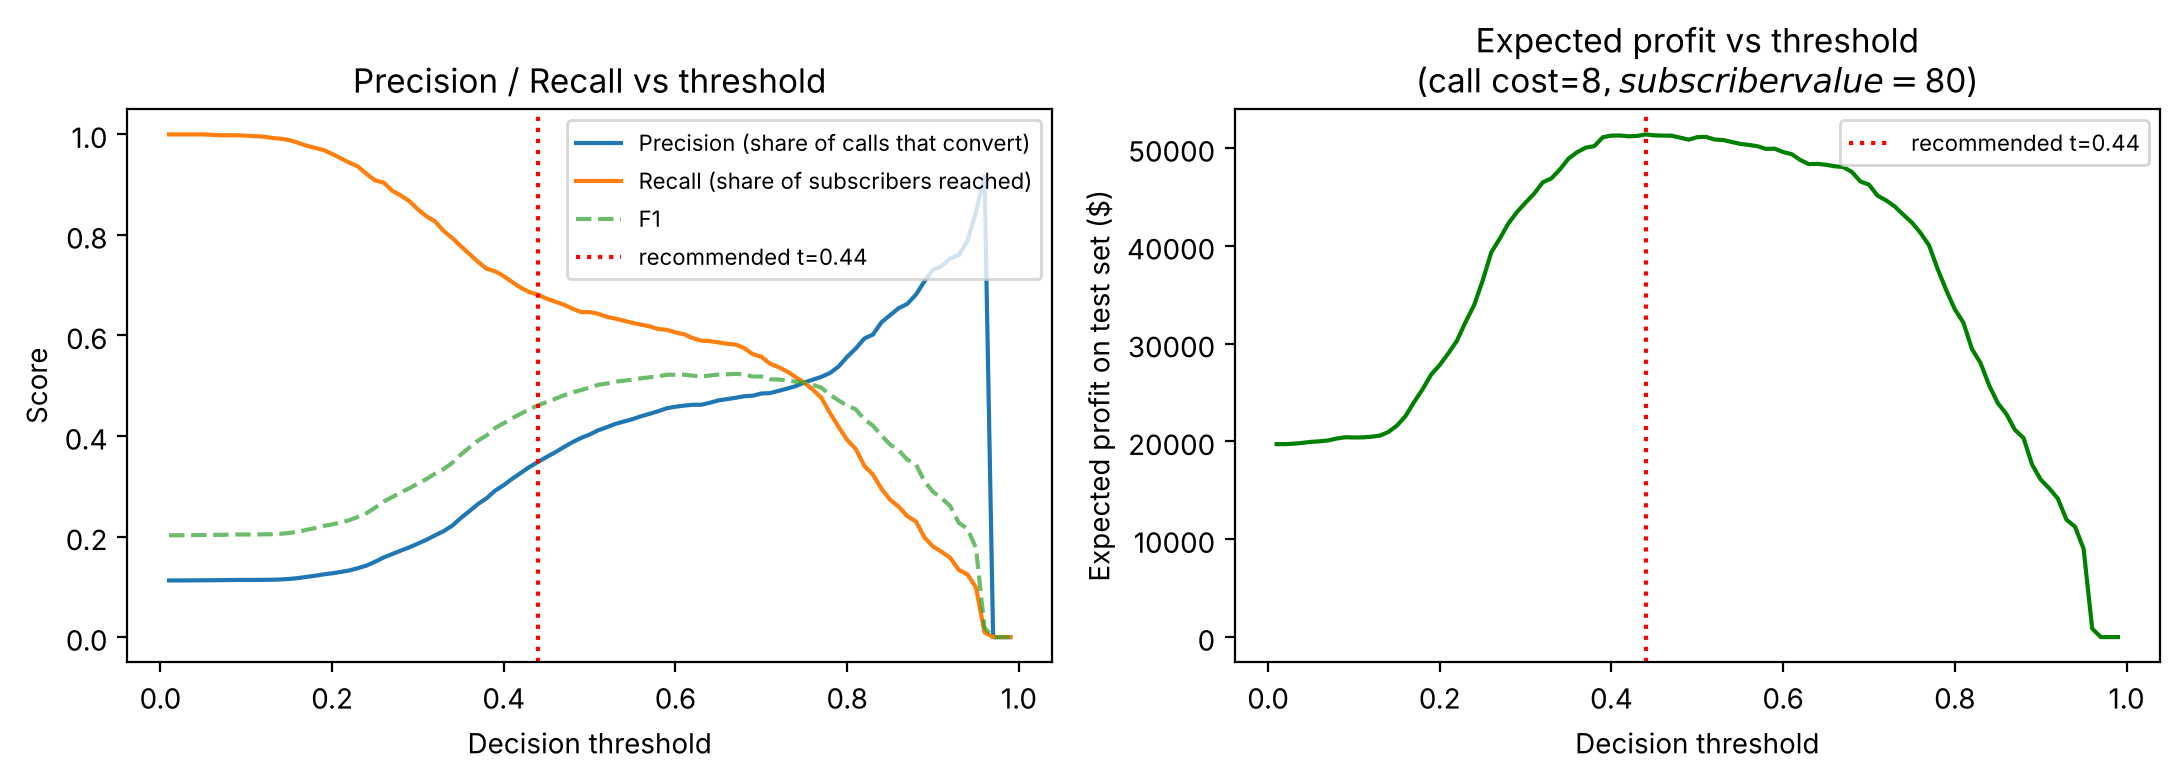

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(threshold_df['threshold'], threshold_df['precision'], label='Precision (share of calls that convert)')
axes[0].plot(threshold_df['threshold'], threshold_df['recall'], label='Recall (share of subscribers reached)')
axes[0].plot(threshold_df['threshold'], threshold_df['f1'], label='F1', linestyle='--', alpha=0.7)
axes[0].axvline(best_row['threshold'], color='red', linestyle=':', label=f"recommended t={best_row['threshold']:.2f}")
axes[0].set_xlabel('Decision threshold')
axes[0].set_ylabel('Score')
axes[0].set_title('Precision / Recall vs threshold')
axes[0].legend(fontsize=8)

axes[1].plot(threshold_df['threshold'], threshold_df['profit'], color='green')
axes[1].axvline(best_row['threshold'], color='red', linestyle=':', label=f"recommended t={best_row['threshold']:.2f}")
axes[1].set_xlabel('Decision threshold')
axes[1].set_ylabel('Expected profit on test set ($)')
axes[1].set_title(f'Expected profit vs threshold\n(call cost=${CALL_COST}, subscriber value=${SUBSCRIBER_VALUE})')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig('threshold_analysis.png', dpi=110)
plt.show()


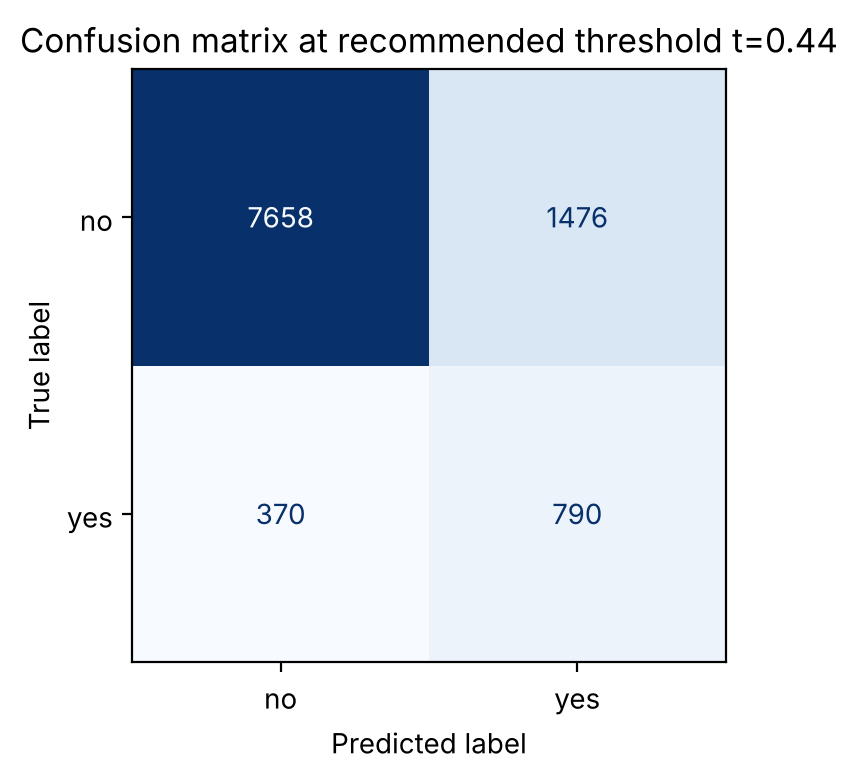

At threshold 0.44:
  Calls made (predicted positive) : 2266 out of 10294 customers
  True subscribers reached (TP)   : 790
  Unnecessary calls (FP)          : 1476
  Missed subscribers (FN)         : 370
  Precision (hit rate on calls)   : 0.349
  Recall (subscribers reached)    : 0.681
  Expected profit                 : $51392

For comparison, the naive default threshold 0.50 gives:
  Calls made: 1861, TP: 750, FP: 1111, profit: $51112


In [17]:
t_star = round(float(best_row['threshold']), 2)
y_pred_star = (y_prob_test >= t_star).astype(int)
cm = confusion_matrix(y_test, y_pred_star)

fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(cm, display_labels=['no', 'yes']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'Confusion matrix at recommended threshold t={t_star}')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=110)
plt.show()

print(f"At threshold {t_star}:")
print(f"  Calls made (predicted positive) : {int(best_row['n_calls'])} out of {len(y_test)} customers")
print(f"  True subscribers reached (TP)   : {int(best_row['tp'])}")
print(f"  Unnecessary calls (FP)          : {int(best_row['fp'])}")
print(f"  Missed subscribers (FN)         : {int(best_row['fn'])}")
print(f"  Precision (hit rate on calls)   : {best_row['precision']:.3f}")
print(f"  Recall (subscribers reached)    : {best_row['recall']:.3f}")
print(f"  Expected profit                 : ${best_row['profit']:.0f}")

default_row = threshold_df.iloc[(threshold_df['threshold'] - 0.5).abs().argmin()]
print(f"\nFor comparison, the naive default threshold 0.50 gives:")
print(f"  Calls made: {int(default_row['n_calls'])}, TP: {int(default_row['tp'])}, FP: {int(default_row['fp'])}, "
      f"profit: ${default_row['profit']:.0f}")


### 3.2 Sensitivity of the recommendation to the cost assumptions

The $8 / $80 figures above are illustrative. Since the optimal threshold is driven entirely by
the **ratio** of subscriber value to call cost, it's useful to see how the recommended
threshold shifts as that ratio changes — a bank can read off its own recommended threshold
once it knows its own figures.

In [18]:
cost_ratios = [2, 5, 10, 15, 20, 30]
sensitivity_rows = []
for ratio in cost_ratios:
    call_cost = 8
    subscriber_value = call_cost * ratio
    profit = threshold_df['tp'] * subscriber_value - threshold_df['fp'] * call_cost
    idx = profit.idxmax()
    sensitivity_rows.append({
        'value_to_cost_ratio': ratio,
        'recommended_threshold': round(threshold_df.loc[idx, 'threshold'], 2),
        'n_calls': int(threshold_df.loc[idx, 'n_calls']),
        'recall': round(threshold_df.loc[idx, 'recall'], 3),
        'precision': round(threshold_df.loc[idx, 'precision'], 3),
    })
sensitivity_df = pd.DataFrame(sensitivity_rows)
sensitivity_df


,value_to_cost_ratio,recommended_threshold,n_calls,recall,precision
0,2,0.68,1392,0.575,0.479
1,5,0.59,1557,0.611,0.455
2,10,0.44,2266,0.681,0.349
3,15,0.35,3807,0.778,0.237
4,20,0.29,5633,0.867,0.179
5,30,0.26,6623,0.904,0.158


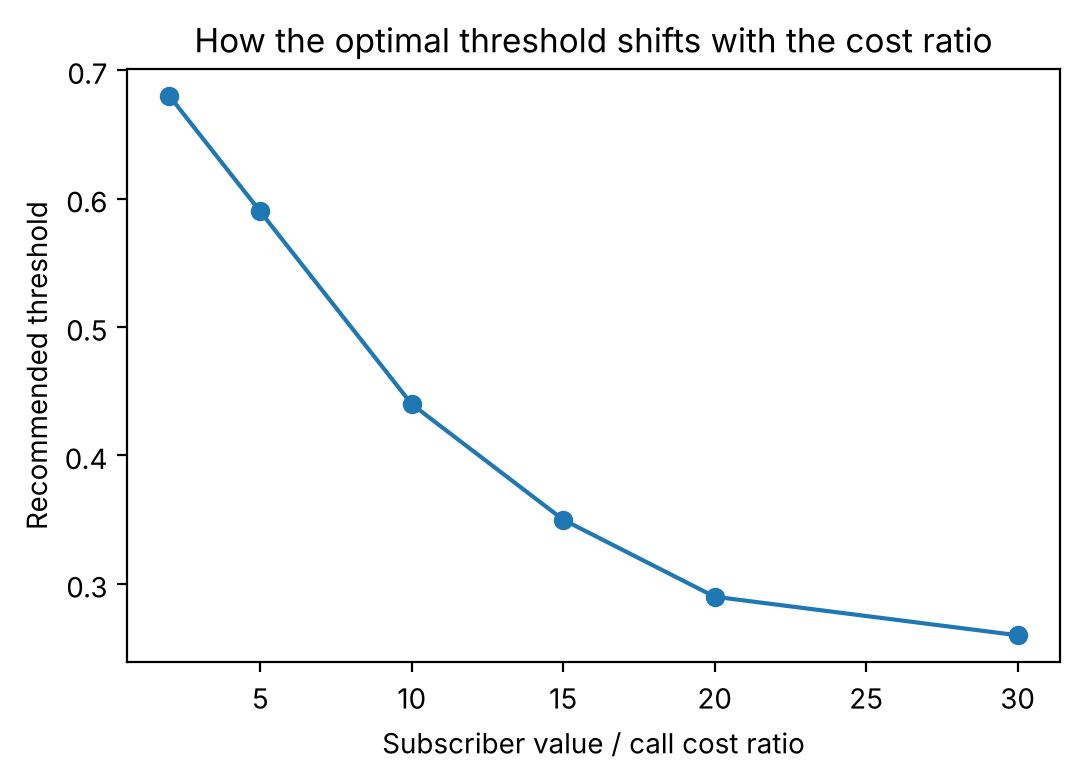

In [19]:
fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(sensitivity_df['value_to_cost_ratio'], sensitivity_df['recommended_threshold'], marker='o')
ax.set_xlabel('Subscriber value / call cost ratio')
ax.set_ylabel('Recommended threshold')
ax.set_title('How the optimal threshold shifts with the cost ratio')
plt.tight_layout()
plt.savefig('threshold_sensitivity.png', dpi=110)
plt.show()


### 3.3 Recommendation and interpretation

**Recommended threshold:** the value printed above as *"Recommended threshold (max expected
profit)"*, derived from the illustrative $8 unnecessary-call cost vs. $80 subscriber value
(a 10:1 ratio).

- It sits **well below the naive default of 0.5**, because missing a subscriber is far more
  costly than making a wasted call — so the model should err on the side of calling more
  people, not fewer.
- Moving the threshold **down** from this point: more subscribers are reached (higher recall),
  but at a steeper rate of unnecessary calls; past a certain point, the extra wasted-call cost
  outweighs the extra subscribers found, and expected profit falls — visible as the profit
  curve turning down for very low thresholds.
- Moving the threshold **up** towards 0.5+ : far fewer calls are made and most are higher-
  confidence hits (high precision), but a large share of genuine subscribers are never called
  at all (low recall) — this is visibly worse under the assumed costs, though it may still be
  preferred if the bank is capacity-constrained (e.g. only has agent-hours to make a fixed, small
  number of calls, in which case the model's *ranking* — calling the highest-probability
  customers first up to the capacity limit — matters more than any single threshold).
- The sensitivity table confirms the directional logic: as the subscriber value grows
  relative to the call cost, the optimal threshold moves lower (call more people), and vice versa.

**Practical recommendation:** adopt the profit-maximising threshold as a starting point, but
replace the illustrative $8/$80 figures with the bank's actual average call cost and actual
average net value of a term deposit subscription before deploying it, and re-run Section 3 —
the code above is written so that only `CALL_COST` and `SUBSCRIBER_VALUE` need to change.
If the campaign is capacity-constrained rather than cost-constrained (a fixed number of agent
hours available), rank customers by predicted probability and call down the list until
capacity is used, rather than applying a fixed threshold.


## Summary

- **Section 1:** the data is clean (no true nulls, few duplicates) but highly imbalanced
  (~11.3% positive). `duration` was dropped as a known leakage variable; `"unknown"` categorical
  values were kept as their own class; a majority-class baseline reaches 88.7% accuracy but
  0% recall and AUC 0.5 — a real model must clear this bar on AUC/recall, not accuracy.
- **Section 2:** Gradient Boosting (HGB) is the top-ranked candidate on cross-validated
  ROC-AUC, narrowly ahead of Random Forest, with Logistic Regression weakest but most
  interpretable; all three were trained without `duration` and evaluated identically.
- **Section 3:** the optimal call threshold is driven by the ratio of subscriber value to
  call cost, not by the default 0.5 cut-off; under illustrative assumptions it sits well below
  0.5, favouring more calls and higher recall, and the notebook shows how to re-derive it from
  the bank's real costs.
